<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRAINING DATASET


,Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
0,Sunny,Warm,Normal,Strong,Warm,Same,Yes
1,Sunny,Warm,High,Strong,Warm,Same,Yes
2,Rainy,Cold,High,Strong,Warm,Change,No
3,Sunny,Warm,High,Strong,Cool,Same,Yes



FINAL SPECIFIC HYPOTHESIS (S)
['Sunny', 'Warm', '?', 'Strong', '?', 'Same']

FINAL GENERAL HYPOTHESIS (G)
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']
['?', '?', '?', '?', '?', 'Same']

VERSION SPACE BOUNDARIES
S = ['Sunny', 'Warm', '?', 'Strong', '?', 'Same']
G = [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]

STEP-BY-STEP RESULTS
Example 1 | Class: Yes | S: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same'] | Number of G hypotheses: 1
Example 2 | Class: Yes | S: ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same'] | Number of G hypotheses: 1
Example 3 | Class: No | S: ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same'] | Number of G hypotheses: 3
Example 4 | Class: Yes | S: ['Sunny', 'Warm', '?', 'Strong', '?', 'Same'] | Number of G hypotheses: 3


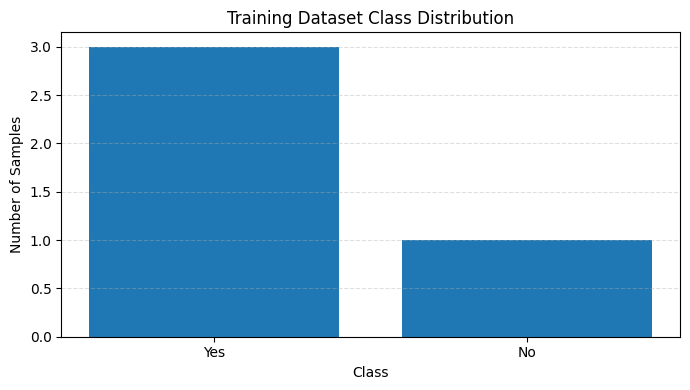

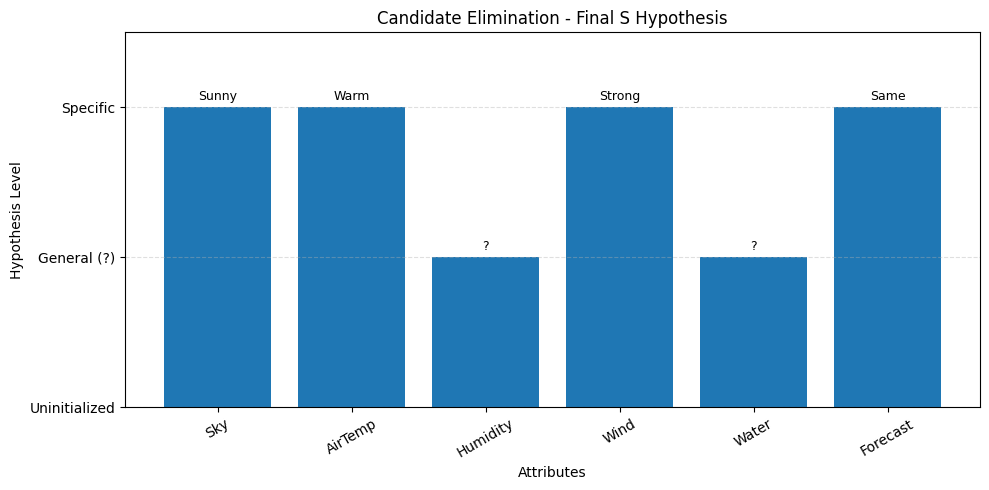

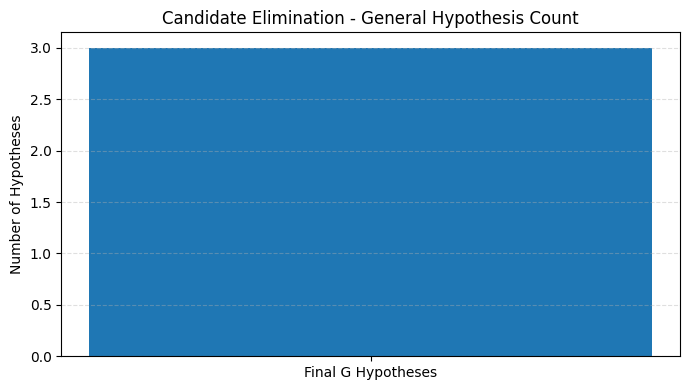

In [1]:
# EXPERIMENT 2: CANDIDATE ELIMINATION ALGORITHM

import pandas as pd
import matplotlib.pyplot as plt

# 1. Training Dataset
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Same'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("TRAINING DATASET")
display(df)

# 2. Separate attributes and target
X = df.iloc[:, :-1].values.tolist()
Y = df.iloc[:, -1].tolist()

n = len(X[0])

# 3. Initialize S and G
S = ['0'] * n
G = [['?' for _ in range(n)]]

steps = []

# 4. Candidate Elimination
for index, (example, label) in enumerate(zip(X, Y)):

    if label == 'Yes':

        # Generalize S using positive example
        for i in range(n):
            if S[i] == '0':
                S[i] = example[i]
            elif S[i] != example[i]:
                S[i] = '?'

        # Remove inconsistent hypotheses from G
        G = [
            g for g in G
            if all(g[i] == '?' or g[i] == example[i]
                   for i in range(n))
        ]

    else:

        # Specialize G using negative example
        new_G = []

        for g in G:
            for i in range(n):

                if g[i] == '?' and S[i] != '?' and S[i] != '0':
                    if S[i] != example[i]:
                        new_h = g.copy()
                        new_h[i] = S[i]
                        new_G.append(new_h)

        G = new_G

    steps.append({
        'Example': index + 1,
        'Class': label,
        'S': S.copy(),
        'G': len(G)
    })

# 5. Display final hypotheses
print("\nFINAL SPECIFIC HYPOTHESIS (S)")
print(S)

print("\nFINAL GENERAL HYPOTHESIS (G)")
for g in G:
    print(g)

print("\nVERSION SPACE BOUNDARIES")
print("S =", S)
print("G =", G)

# 6. Display step-by-step progress
print("\nSTEP-BY-STEP RESULTS")
for step in steps:
    print(
        f"Example {step['Example']} | "
        f"Class: {step['Class']} | "
        f"S: {step['S']} | "
        f"Number of G hypotheses: {step['G']}"
    )

# 7. Matplotlib Bar Graph: Positive vs Negative Samples
plt.figure(figsize=(7, 4))

counts = df['EnjoySport'].value_counts().reindex(
    ['Yes', 'No'], fill_value=0
)

plt.bar(counts.index, counts.values)
plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 8. Matplotlib Graph: Specific Hypothesis
plt.figure(figsize=(10, 5))

values = [0 if x == '0' else 1 if x == '?' else 2
          for x in S]

bars = plt.bar(df.columns[:-1], values)

for bar, value in zip(bars, S):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        str(value),
        ha='center',
        fontsize=9
    )

plt.title("Candidate Elimination - Final S Hypothesis")
plt.xlabel("Attributes")
plt.ylabel("Hypothesis Level")
plt.yticks([0, 1, 2], ['Uninitialized', 'General (?)', 'Specific'])
plt.ylim(0, 2.5)
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 9. Bar Graph: General Hypothesis Count
plt.figure(figsize=(7, 4))

plt.bar(
    ['Final G Hypotheses'],
    [len(G)]
)

plt.title("Candidate Elimination - General Hypothesis Count")
plt.ylabel("Number of Hypotheses")
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()